In [2]:
# Install the pretrained face-recognition runtime

!pip -q install insightface onnxruntime

In [3]:
# Load the clean protocol and initialize the degradation evaluation runtime

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_lfw_people
from tqdm.auto import tqdm
from insightface.app import FaceAnalysis

random_seed = 42

lfw = fetch_lfw_people(
    min_faces_per_person=5,
    color=True,
    resize=1.0,
    download_if_missing=True
)

images = lfw.images
labels = lfw.target
identity_names = lfw.target_names

data_directory = Path(
    "/content/drive/MyDrive/Colab Notebooks/face_degradation/data"
)

results_directory = Path(
    "/content/drive/MyDrive/Colab Notebooks/face_degradation/results"
)

split_path = data_directory / "lfw_gallery_probe_split.csv"
gallery_probe_split = pd.read_csv(split_path)

gallery_metadata = gallery_probe_split[
    gallery_probe_split["split"] == "gallery"
].copy()

probe_metadata = gallery_probe_split[
    gallery_probe_split["split"] == "probe"
].copy()

gallery_indices = gallery_metadata["image_index"].to_numpy()
probe_indices = probe_metadata["image_index"].to_numpy()

gallery_images = images[gallery_indices]
probe_images = images[probe_indices]

gallery_identity_ids = gallery_metadata[
    "identity_id"
].to_numpy()

probe_identity_ids = probe_metadata[
    "identity_id"
].to_numpy()

gallery_embeddings = np.load(
    results_directory / "gallery_arcface_embeddings.npy"
)

probe_embeddings_clean = np.load(
    results_directory / "probe_arcface_embeddings.npy"
)

face_app = FaceAnalysis(
    name="buffalo_l",
    providers=["CPUExecutionProvider"]
)

face_app.prepare(
    ctx_id=-1,
    det_size=(320, 320)
)

recognition_model = face_app.models["recognition"]

print(f"Gallery images: {gallery_images.shape}")
print(f"Probe images: {probe_images.shape}")
print(f"Gallery embeddings: {gallery_embeddings.shape}")
print(f"Clean probe embeddings: {probe_embeddings_clean.shape}")
print("Evaluation runtime initialized.")

download_path: /root/.insightface/models/buffalo_l


100%|██████████| 281857/281857 [00:06<00:00, 42608.67KB/s]


Gallery images: (1269, 125, 94, 3)
Probe images: (846, 125, 94, 3)
Gallery embeddings: (1269, 512)
Clean probe embeddings: (846, 512)
Evaluation runtime initialized.


In [4]:
# Reconstruct normalized gallery templates for degraded-probe evaluation

recognition_model = face_app.models["recognition"]


def normalize_vectors(vectors):
    norms = np.linalg.norm(
        vectors,
        axis=1,
        keepdims=True
    )

    return vectors / np.maximum(
        norms,
        1e-12
    )


identity_ids = np.sort(
    gallery_metadata["identity_id"].unique()
)

gallery_templates = []
template_identity_ids = []

for identity_id in identity_ids:
    identity_embeddings = gallery_embeddings[
        gallery_identity_ids == identity_id
    ]

    identity_template = identity_embeddings.mean(
        axis=0,
        keepdims=True
    )

    identity_template = normalize_vectors(
        identity_template
    )[0]

    gallery_templates.append(identity_template)
    template_identity_ids.append(identity_id)

gallery_templates = np.vstack(gallery_templates)
template_identity_ids = np.array(template_identity_ids)

print(f"Gallery template matrix: {gallery_templates.shape}")
print(f"Template identities: {len(template_identity_ids)}")

Gallery template matrix: (423, 512)
Template identities: 423


In [5]:
# Define controlled degradation operators for probe images

def ensure_valid_image(image):
    return np.clip(
        image,
        0.0,
        1.0
    ).astype(np.float32)


def apply_blur(image, severity):
    parameters = {
        "mild": (5, 1.0),
        "moderate": (9, 2.5),
        "severe": (15, 4.0)
    }

    kernel_size, sigma = parameters[severity]

    degraded = cv2.GaussianBlur(
        image,
        (kernel_size, kernel_size),
        sigmaX=sigma,
        sigmaY=sigma
    )

    return ensure_valid_image(degraded)


def apply_jpeg_compression(image, severity):
    quality_levels = {
        "mild": 60,
        "moderate": 30,
        "severe": 10
    }

    image_uint8 = np.clip(
        image * 255,
        0,
        255
    ).astype(np.uint8)

    image_bgr = cv2.cvtColor(
        image_uint8,
        cv2.COLOR_RGB2BGR
    )

    success, encoded_image = cv2.imencode(
        ".jpg",
        image_bgr,
        [cv2.IMWRITE_JPEG_QUALITY, quality_levels[severity]]
    )

    if not success:
        raise RuntimeError("JPEG encoding failed.")

    decoded_bgr = cv2.imdecode(
        encoded_image,
        cv2.IMREAD_COLOR
    )

    decoded_rgb = cv2.cvtColor(
        decoded_bgr,
        cv2.COLOR_BGR2RGB
    )

    return ensure_valid_image(
        decoded_rgb / 255.0
    )


def apply_resolution_reduction(image, severity):
    scale_levels = {
        "mild": 0.75,
        "moderate": 0.50,
        "severe": 0.25
    }

    scale = scale_levels[severity]

    height, width = image.shape[:2]

    reduced = cv2.resize(
        image,
        (
            max(2, int(width * scale)),
            max(2, int(height * scale))
        ),
        interpolation=cv2.INTER_AREA
    )

    restored = cv2.resize(
        reduced,
        (width, height),
        interpolation=cv2.INTER_LINEAR
    )

    return ensure_valid_image(restored)


def apply_illumination_change(image, severity):
    brightness_levels = {
        "mild": 0.85,
        "moderate": 0.65,
        "severe": 0.45
    }

    degraded = (
        image * brightness_levels[severity]
        + 0.02
    )

    return ensure_valid_image(degraded)


def apply_gaussian_noise(image, severity, random_generator):
    noise_levels = {
        "mild": 0.025,
        "moderate": 0.060,
        "severe": 0.110
    }

    noise = random_generator.normal(
        loc=0.0,
        scale=noise_levels[severity],
        size=image.shape
    )

    return ensure_valid_image(image + noise)


degradation_functions = {
    "blur": apply_blur,
    "jpeg_compression": apply_jpeg_compression,
    "resolution_reduction": apply_resolution_reduction,
    "illumination": apply_illumination_change
}

severity_levels = [
    "mild",
    "moderate",
    "severe"
]

print("Degradations:", list(degradation_functions))
print("Severity levels:", severity_levels)

Degradations: ['blur', 'jpeg_compression', 'resolution_reduction', 'illumination']
Severity levels: ['mild', 'moderate', 'severe']


In [6]:
# Define direct batch embedding extraction for degraded probes

def prepare_for_recognition(image):
    image_uint8 = np.clip(
        image * 255,
        0,
        255
    ).astype(np.uint8)

    image_bgr = cv2.cvtColor(
        image_uint8,
        cv2.COLOR_RGB2BGR
    )

    return cv2.resize(
        image_bgr,
        recognition_model.input_size,
        interpolation=cv2.INTER_CUBIC
    )


def extract_direct_embeddings(
    dataset_images,
    batch_size=64
):
    prepared_images = [
        prepare_for_recognition(image)
        for image in dataset_images
    ]

    embedding_batches = []

    for start_index in tqdm(
        range(0, len(prepared_images), batch_size),
        desc="Extracting embeddings"
    ):
        batch_images = prepared_images[
            start_index:start_index + batch_size
        ]

        batch_embeddings = recognition_model.get_feat(
            batch_images
        )

        embedding_batches.append(batch_embeddings)

    embeddings = np.vstack(embedding_batches)

    norms = np.linalg.norm(
        embeddings,
        axis=1,
        keepdims=True
    )

    return embeddings / np.maximum(
        norms,
        1e-12
    )

In [7]:
# Define identification metrics for each degradation condition

def evaluate_identification(
    probe_embeddings,
    probe_identity_ids
):
    similarity_matrix = (
        probe_embeddings @ gallery_templates.T
    )

    ranked_positions = np.argsort(
        similarity_matrix,
        axis=1
    )[:, ::-1]

    ranked_identity_ids = (
        template_identity_ids[ranked_positions]
    )

    top_1_predictions = ranked_identity_ids[:, 0]

    rank_1_correct = (
        top_1_predictions == probe_identity_ids
    )

    rank_5_correct = np.any(
        ranked_identity_ids[:, :5]
        == probe_identity_ids[:, None],
        axis=1
    )

    true_positions = np.array([
        np.where(
            template_identity_ids == identity_id
        )[0][0]
        for identity_id in probe_identity_ids
    ])

    true_similarity = similarity_matrix[
        np.arange(len(probe_identity_ids)),
        true_positions
    ]

    strongest_impostor_similarity = []

    for row_index, true_position in enumerate(
        true_positions
    ):
        impostor_scores = np.delete(
            similarity_matrix[row_index],
            true_position
        )

        strongest_impostor_similarity.append(
            impostor_scores.max()
        )

    strongest_impostor_similarity = np.array(
        strongest_impostor_similarity
    )

    similarity_margin = (
        true_similarity
        - strongest_impostor_similarity
    )

    return {
        "rank_1_accuracy": rank_1_correct.mean(),
        "rank_5_accuracy": rank_5_correct.mean(),
        "mean_true_similarity": true_similarity.mean(),
        "mean_strongest_impostor_similarity": (
            strongest_impostor_similarity.mean()
        ),
        "mean_similarity_margin": similarity_margin.mean(),
        "negative_margin_count": (
            similarity_margin < 0
        ).sum(),
        "rank_1_correct_count": rank_1_correct.sum(),
        "rank_5_correct_count": rank_5_correct.sum()
    }

In [10]:
# Run the degradation experiments with checkpointed outputs

experiment_rows = []

experiment_results_path = (
    results_directory / "degradation_experiment_results.csv"
)

for degradation_name, degradation_function in (
    degradation_functions.items()
):
    for severity in severity_levels:
        condition_name = (
            f"{degradation_name}_{severity}"
        )

        embedding_path = (
            results_directory
            / f"probe_embeddings_{condition_name}.npy"
        )

        print(f"\nRunning condition: {condition_name}")

        if embedding_path.exists():
            degraded_embeddings = np.load(
                embedding_path
            )

            print("Loaded cached embeddings.")
        else:
            degraded_probe_images = []

            for probe_index, image in enumerate(
                probe_images
            ):
                if degradation_name == "gaussian_noise":
                    random_generator = np.random.default_rng(
                        random_seed + probe_index
                    )

                    degraded_image = (
                        apply_gaussian_noise(
                            image,
                            severity,
                            random_generator
                        )
                    )
                else:
                    degraded_image = degradation_function(
                        image,
                        severity
                    )

                degraded_probe_images.append(
                    degraded_image
                )

            degraded_probe_images = np.stack(
                degraded_probe_images
            )

            degraded_embeddings = (
                extract_direct_embeddings(
                    degraded_probe_images
                )
            )

            np.save(
                embedding_path,
                degraded_embeddings
            )

            print("Saved new embeddings.")

        metrics = evaluate_identification(
            degraded_embeddings,
            probe_identity_ids
        )

        metrics["degradation"] = degradation_name
        metrics["severity"] = severity
        metrics["condition"] = condition_name

        experiment_rows.append(metrics)

        pd.DataFrame(experiment_rows).to_csv(
            experiment_results_path,
            index=False
        )

        print(
            f"Rank-1: "
            f"{metrics['rank_1_accuracy']:.4f} | "
            f"Rank-5: "
            f"{metrics['rank_5_accuracy']:.4f} | "
            f"Margin: "
            f"{metrics['mean_similarity_margin']:.4f}"
        )

print(
    f"\nSaved checkpoint results to: "
    f"{experiment_results_path}"
)


Running condition: blur_mild
Loaded cached embeddings.
Rank-1: 0.9586 | Rank-5: 0.9775 | Margin: 0.2854

Running condition: blur_moderate
Loaded cached embeddings.
Rank-1: 0.9480 | Rank-5: 0.9728 | Margin: 0.2380

Running condition: blur_severe
Loaded cached embeddings.
Rank-1: 0.8830 | Rank-5: 0.9492 | Margin: 0.1462

Running condition: jpeg_compression_mild
Loaded cached embeddings.
Rank-1: 0.9539 | Rank-5: 0.9764 | Margin: 0.2826

Running condition: jpeg_compression_moderate
Loaded cached embeddings.
Rank-1: 0.9527 | Rank-5: 0.9740 | Margin: 0.2709

Running condition: jpeg_compression_severe
Loaded cached embeddings.
Rank-1: 0.9196 | Rank-5: 0.9551 | Margin: 0.2010

Running condition: resolution_reduction_mild
Loaded cached embeddings.
Rank-1: 0.9586 | Rank-5: 0.9764 | Margin: 0.2888

Running condition: resolution_reduction_moderate
Loaded cached embeddings.
Rank-1: 0.9574 | Rank-5: 0.9775 | Margin: 0.2863

Running condition: resolution_reduction_severe
Loaded cached embeddings.
Ra

In [9]:
# Verify cached degradation embeddings

from pathlib import Path

results_directory = Path(
    "/content/drive/MyDrive/Colab Notebooks/face_degradation/results"
)

cached_embeddings = sorted(
    results_directory.glob("probe_embeddings_*.npy")
)

print(f"Cached embedding files: {len(cached_embeddings)}")

for file_path in cached_embeddings:
    print(file_path.name)

Cached embedding files: 12
probe_embeddings_blur_mild.npy
probe_embeddings_blur_moderate.npy
probe_embeddings_blur_severe.npy
probe_embeddings_illumination_mild.npy
probe_embeddings_illumination_moderate.npy
probe_embeddings_illumination_severe.npy
probe_embeddings_jpeg_compression_mild.npy
probe_embeddings_jpeg_compression_moderate.npy
probe_embeddings_jpeg_compression_severe.npy
probe_embeddings_resolution_reduction_mild.npy
probe_embeddings_resolution_reduction_moderate.npy
probe_embeddings_resolution_reduction_severe.npy


In [11]:
# Load and organize the complete degradation results

degradation_results = pd.read_csv(
    results_directory
    / "degradation_experiment_results.csv"
)

degradation_results = degradation_results[
    [
        "degradation",
        "severity",
        "rank_1_accuracy",
        "rank_5_accuracy",
        "mean_true_similarity",
        "mean_strongest_impostor_similarity",
        "mean_similarity_margin",
        "negative_margin_count",
        "rank_1_correct_count",
        "rank_5_correct_count"
    ]
]

display(
    degradation_results.sort_values(
        [
            "degradation",
            "severity"
        ]
    )
)

,degradation,severity,rank_1_accuracy,rank_5_accuracy,mean_true_similarity,mean_strongest_impostor_similarity,mean_similarity_margin,negative_margin_count,rank_1_correct_count,rank_5_correct_count
0,blur,mild,0.958629,0.977541,0.554866,0.269416,0.285450,35,811,827
1,blur,moderate,0.947991,0.972813,0.497292,0.259333,0.237960,44,802,823
2,blur,severe,0.882979,0.949173,0.394220,0.248036,0.146183,99,747,803
9,illumination,mild,0.958629,0.977541,0.560851,0.273216,0.287635,35,811,827
10,illumination,moderate,0.953901,0.975177,0.557125,0.271889,0.285236,39,807,825
11,illumination,severe,0.949173,0.972813,0.548730,0.269079,0.279651,43,803,823
3,jpeg_compression,mild,0.953901,0.976359,0.555060,0.272481,0.282579,39,807,826
4,jpeg_compression,moderate,0.952719,0.973995,0.540317,0.269447,0.270869,40,806,824
5,jpeg_compression,severe,0.919622,0.955083,0.464794,0.263784,0.201009,68,778,808
6,resolution_reduction,mild,0.958629,0.976359,0.560154,0.271317,0.288838,35,811,826


In [12]:
# Add the clean baseline for direct comparison

clean_summary = pd.read_csv(
    results_directory
    / "clean_arcface_baseline_summary.csv"
)

clean_rank_1 = clean_summary.loc[
    clean_summary["metric"] == "rank_1_accuracy",
    "value"
].iloc[0]

clean_rank_5 = clean_summary.loc[
    clean_summary["metric"] == "rank_5_accuracy",
    "value"
].iloc[0]

clean_result = pd.DataFrame({
    "degradation": ["clean_baseline"],
    "severity": ["none"],
    "rank_1_accuracy": [clean_rank_1],
    "rank_5_accuracy": [clean_rank_5]
})

comparison_results = pd.concat(
    [
        clean_result,
        degradation_results[
            [
                "degradation",
                "severity",
                "rank_1_accuracy",
                "rank_5_accuracy"
            ]
        ]
    ],
    ignore_index=True
)

display(comparison_results)

,degradation,severity,rank_1_accuracy,rank_5_accuracy
0,clean_baseline,none,0.958629,0.978723
1,blur,mild,0.958629,0.977541
2,blur,moderate,0.947991,0.972813
3,blur,severe,0.882979,0.949173
4,jpeg_compression,mild,0.953901,0.976359
5,jpeg_compression,moderate,0.952719,0.973995
6,jpeg_compression,severe,0.919622,0.955083
7,resolution_reduction,mild,0.958629,0.976359
8,resolution_reduction,moderate,0.957447,0.977541
9,resolution_reduction,severe,0.944444,0.973995


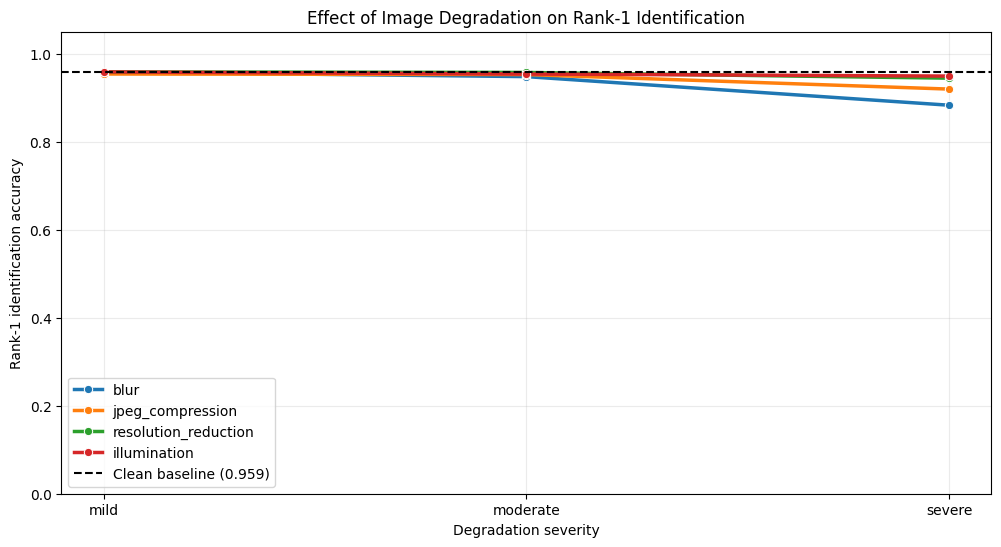

In [13]:
# Plot Rank-1 accuracy by degradation severity

import seaborn as sns

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=degradation_results,
    x="severity",
    y="rank_1_accuracy",
    hue="degradation",
    marker="o",
    linewidth=2.5
)

plt.axhline(
    clean_rank_1,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Clean baseline ({clean_rank_1:.3f})"
)

plt.xlabel("Degradation severity")
plt.ylabel("Rank-1 identification accuracy")
plt.title(
    "Effect of Image Degradation on Rank-1 Identification"
)
plt.ylim(0, 1.05)
plt.grid(alpha=0.25)
plt.legend()
plt.show()

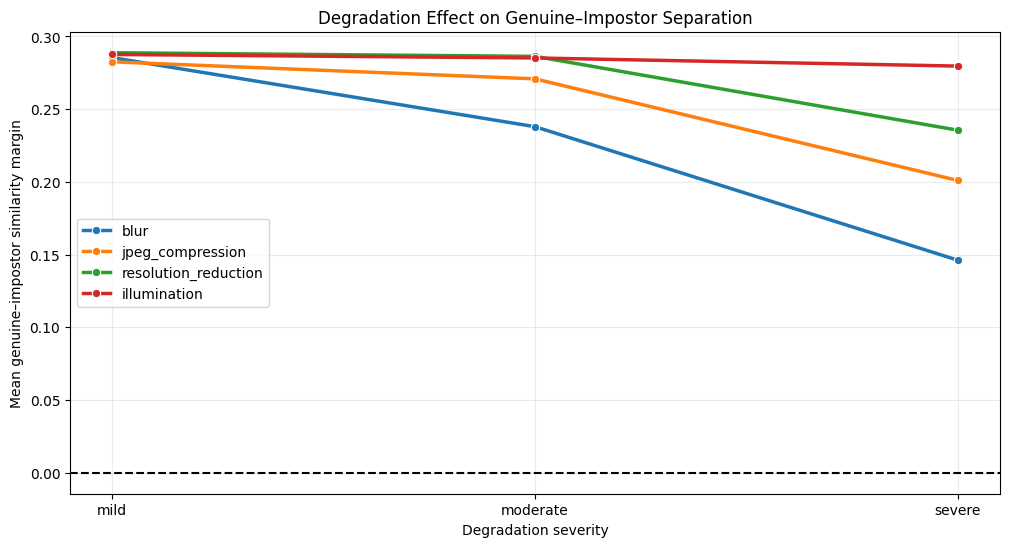

In [14]:
# Plot similarity-margin degradation

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=degradation_results,
    x="severity",
    y="mean_similarity_margin",
    hue="degradation",
    marker="o",
    linewidth=2.5
)

plt.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Degradation severity")
plt.ylabel("Mean genuine–impostor similarity margin")
plt.title(
    "Degradation Effect on Genuine–Impostor Separation"
)
plt.grid(alpha=0.25)
plt.legend()
plt.show()

In [15]:
# Save the final experiment table

final_results_path = (
    results_directory
    / "final_degradation_experiment_results.csv"
)

degradation_results.to_csv(
    final_results_path,
    index=False
)

comparison_results.to_csv(
    results_directory
    / "clean_vs_degraded_comparison.csv",
    index=False
)

print(
    f"Saved final degradation results to: "
    f"{final_results_path}"
)

Saved final degradation results to: /content/drive/MyDrive/Colab Notebooks/face_degradation/results/final_degradation_experiment_results.csv
